# Estimasi Klorofil-a Sentinel-2 di Segara Anakan, Cilacap
**UAS Sistem Informasi Geografi — Opsi B (Ecological Layer)**

Workflow: Sentinel-2 SR (GEE) → masking awan (SCL) → masking badan air (NDWI) → indeks NDCI → estimasi Chl-a → komposit median bulanan → peta & grafik.

**Cara pakai:** jalankan sel dari atas ke bawah. Isi `PROJECT_ID` di sel 2 dengan Project ID Google Cloud yang terdaftar di Earth Engine.

## 1. Setup & autentikasi

In [7]:
!pip -q install geemap
import ee, geemap
ee.Authenticate()   # klik link, login Google, salin kode ke kotak input


## 2. Parameter (ubah di sini)

In [8]:
PROJECT_ID = 'tugas-sig-515914'   # <-- GANTI

ee.Initialize(project=PROJECT_ID)

# Area studi Segara Anakan (perkiraan kasar: [barat, selatan, timur, utara]).
# Cek di peta (sel 4) dan sesuaikan bila perlu.
roi = ee.Geometry.Rectangle([108.77, -7.82, 109.02, -7.63])

YEAR = 2025
M_WET, M_DRY = 2, 8           # bulan pembanding: musim hujan vs kemarau
CLOUD_MAX = 60                # batas % awan per scene
VIS = {'min': 0, 'max': 40,
       'palette': ['#00429d', '#4ac16d', '#fde725', '#ff6f3c', '#b2182b']}


## 3. Fungsi pra-pemrosesan & estimasi Chl-a

In [9]:
def prep(img):
    scl = img.select('SCL')   # buang bayangan awan(3), awan(8,9), cirrus(10), salju(11)
    clear = (scl.neq(3).And(scl.neq(8)).And(scl.neq(9))
                .And(scl.neq(10)).And(scl.neq(11)))
    sr = img.select(['B3', 'B4', 'B5', 'B8']).divide(10000)
    ndwi = sr.normalizedDifference(['B3', 'B8'])            # mask badan air
    ndci = sr.normalizedDifference(['B5', 'B4']).rename('NDCI')
    # Mishra & Mishra (2012): estimasi relatif, belum dikalibrasi lokal
    chl = ndci.expression('14.039 + 86.115*x + 194.325*x*x',
                          {'x': ndci}).rename('chl_a')
    return chl.updateMask(clear).updateMask(ndwi.gt(0.1))

def month_col(y, m):
    start = ee.Date.fromYMD(y, m, 1)
    return (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
            .filterBounds(roi)
            .filterDate(start, start.advance(1, 'month'))
            .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', CLOUD_MAX)))

def monthly(y, m):
    # median: lebih tahan outlier & sisa awan dibanding rata-rata
    return month_col(y, m).map(prep).median().clip(roi)

for m in (M_WET, M_DRY):
    print(f'Bulan {m}/{YEAR}: {month_col(YEAR, m).size().getInfo()} scene Sentinel-2')


Bulan 2/2025: 1 scene Sentinel-2
Bulan 8/2025: 3 scene Sentinel-2


## 4. Peta interaktif (cek lokasi ROI di sini)

In [10]:
Map = geemap.Map()
Map.centerObject(roi, 11)
Map.addLayer(roi, {'color': 'white'}, 'ROI', False)
Map.addLayer(monthly(YEAR, M_WET), VIS, f'Chl-a bulan {M_WET}/{YEAR} (hujan)')
Map.addLayer(monthly(YEAR, M_DRY), VIS, f'Chl-a bulan {M_DRY}/{YEAR} (kemarau)')
Map.add_colorbar(VIS, label='Chl-a estimasi (mg/m³)')
Map.addLayerControl()
Map


Map(center=[-7.725011039751678, 108.89499999999998], controls=(WidgetControl(options=['position', 'transparent…

## 5. Grafik rata-rata bulanan (time series)

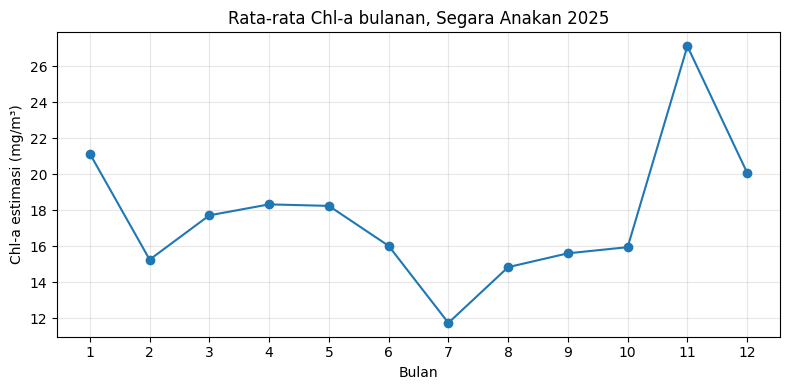

,bulan,jumlah_scene,chl_a_mean
0,1,1,21.136054
1,2,1,15.257746
2,3,2,17.717210
3,4,4,18.325063
4,5,5,18.240698
5,6,2,16.021935
6,7,4,11.745288
7,8,3,14.840097
8,9,4,15.608054
9,10,2,15.948985


In [11]:
import pandas as pd, matplotlib.pyplot as plt

rows = []
for m in range(1, 13):
    n = month_col(YEAR, m).size().getInfo()
    v = None
    if n > 0:
        v = (monthly(YEAR, m)
             .reduceRegion(ee.Reducer.mean(), roi, 20, maxPixels=1e9)
             .get('chl_a').getInfo())
    rows.append({'bulan': m, 'jumlah_scene': n, 'chl_a_mean': v})
df = pd.DataFrame(rows)
df.to_csv('chla_bulanan.csv', index=False)

ax = df.plot(x='bulan', y='chl_a_mean', marker='o', figsize=(8, 4),
             legend=False, title=f'Rata-rata Chl-a bulanan, Segara Anakan {YEAR}')
ax.set_xticks(range(1, 13)); ax.set_xlabel('Bulan')
ax.set_ylabel('Chl-a estimasi (mg/m³)'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('grafik_chla_bulanan.png', dpi=300); plt.show()
df


## 6. Peta berkaidah kartografi (judul, panah utara, skala, legenda, sumber)

Generating URL ...
Please wait ...
Data downloaded to /content/chla_2025_02.tif
Generating URL ...
Please wait ...
Data downloaded to /content/chla_2025_08.tif


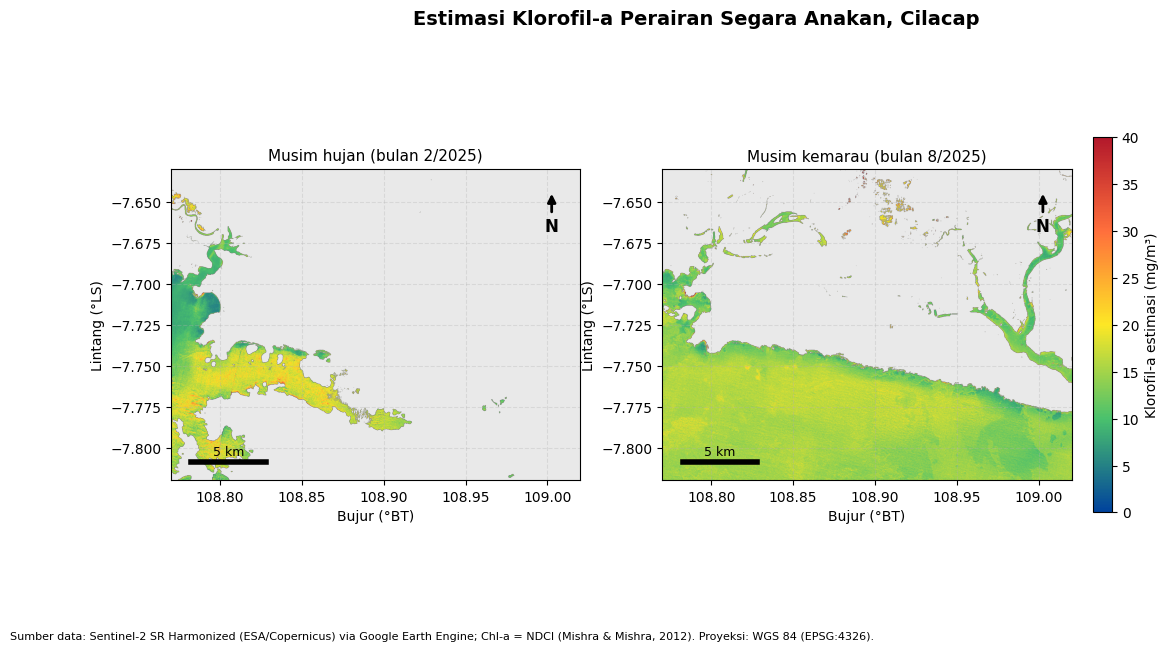

In [12]:
!pip -q install rasterio
import numpy as np, rasterio, math
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable

cmap = LinearSegmentedColormap.from_list('chl', VIS['palette'])
norm = Normalize(VIS['min'], VIS['max'])
NODATA = -9999

def download(y, m):
    fn = f'chla_{y}_{m:02d}.tif'
    img = monthly(y, m).toFloat().unmask(NODATA)
    geemap.ee_export_image(img, filename=fn, scale=20, region=roi,
                           crs='EPSG:4326', file_per_band=False)
    return fn

def draw(ax, fn, title):
    with rasterio.open(fn) as src:
        a = src.read(1).astype(float); b = src.bounds
    a[a == NODATA] = np.nan
    ax.imshow(np.ma.masked_invalid(a), cmap=cmap, norm=norm,
              extent=[b.left, b.right, b.bottom, b.top])
    ax.set_facecolor('#e9e9e9')            # abu-abu = darat / tidak ada data
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Bujur (°BT)'); ax.set_ylabel('Lintang (°LS)')
    ax.grid(alpha=.3, ls='--')
    # panah utara
    ax.annotate('N', xy=(.93, .93), xytext=(.93, .80), xycoords='axes fraction',
                ha='center', fontsize=12, fontweight='bold',
                arrowprops=dict(arrowstyle='-|>', lw=2, color='k'))
    # skala 5 km
    lat = (b.top + b.bottom) / 2
    deg = 5 / (111.32 * math.cos(math.radians(lat)))
    x0 = b.left + (b.right - b.left) * .05
    y0 = b.bottom + (b.top - b.bottom) * .06
    ax.plot([x0, x0 + deg], [y0, y0], 'k-', lw=4)
    ax.text(x0 + deg / 2, y0 + (b.top - b.bottom) * .02, '5 km', ha='center', fontsize=9)

f1, f2 = download(YEAR, M_WET), download(YEAR, M_DRY)
fig, axs = plt.subplots(1, 2, figsize=(14, 6.5))
draw(axs[0], f1, f'Musim hujan (bulan {M_WET}/{YEAR})')
draw(axs[1], f2, f'Musim kemarau (bulan {M_DRY}/{YEAR})')
fig.suptitle('Estimasi Klorofil-a Perairan Segara Anakan, Cilacap', fontsize=14, fontweight='bold')
cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=axs, shrink=.75, pad=.02)
cb.set_label('Klorofil-a estimasi (mg/m³)')
fig.text(.01, .01, 'Sumber data: Sentinel-2 SR Harmonized (ESA/Copernicus) via Google Earth Engine; '
         'Chl-a = NDCI (Mishra & Mishra, 2012). Proyeksi: WGS 84 (EPSG:4326).', fontsize=8)
plt.savefig('peta_chla_segara_anakan.png', dpi=300, bbox_inches='tight'); plt.show()


## 7. Ringkasan statistik (untuk slide & pembahasan)

In [13]:
stats = []
for m, label in ((M_WET, 'Hujan'), (M_DRY, 'Kemarau')):
    r = (monthly(YEAR, m).reduceRegion(
            ee.Reducer.mean().combine(ee.Reducer.median(), sharedInputs=True)
                            .combine(ee.Reducer.max(), sharedInputs=True),
            roi, 20, maxPixels=1e9).getInfo())
    stats.append({'musim': label, 'bulan': m, **{k: round(v, 2) if v is not None else None
                                                 for k, v in r.items()}})
pd.DataFrame(stats)


,musim,bulan,chl_a_max,chl_a_mean,chl_a_median
0,Hujan,2,79.63,15.26,15.75
1,Kemarau,8,66.91,14.84,14.87


## Catatan keterbatasan (cantumkan di presentasi & artikel)
- Rumus Chl-a berasal dari studi di perairan lain dan **belum divalidasi data lapangan** Segara Anakan, jadi hasil dibaca sebagai **estimasi relatif / indeks produktivitas**.
- Awan tropis mengurangi jumlah scene; periksa kolom `jumlah_scene` sebelum menafsirkan bulan tertentu.
- Perairan keruh dan dangkal (sedimen, mangrove) dapat membiaskan estimasi.

## Pengumpulan
Upload notebook ini + `peta_chla_segara_anakan.png` + `grafik_chla_bulanan.png` + `chla_bulanan.csv` ke repository GitHub (File → Save a copy in GitHub).